## Mobiles & laptop Sales Data
#### This dataset contains informations about laptops and mobile phones .

### Import Libraries

In [29]:
import pandas as pd
import numpy as np

### Load Data

In [30]:
df=pd.read_csv('mobile_sales_data.csv')
df.head(2)

,Product,Brand,Product Code,Product Specification,Price,Inward Date,Dispatch Date,Quantity Sold,Customer Name,Customer Location,Region,Core Specification,Processor Specification,RAM,ROM,SSD
0,Mobile Phone,Motorola,88EB4558,Site candidate activity company there bit insi...,78570,2023-08-02,2023-08-03,6,William Hess,South Kelsey,Central,NaN,Snapdragon 7 Gen,12GB,128GB,NaN
1,Laptop,Oppo,416DFEEB,Beat put care fight affect address his.,44613,2023-10-03,2023-10-06,1,Larry Smith,North Lisa,South,Ryzen 5,Ryzen 5,8GB,512GB,256GB


#### Review Data

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Product                  50000 non-null  str  
 1   Brand                    50000 non-null  str  
 2   Product Code             50000 non-null  str  
 3   Product Specification    50000 non-null  str  
 4   Price                    50000 non-null  int64
 5   Inward Date              50000 non-null  str  
 6   Dispatch Date            50000 non-null  str  
 7   Quantity Sold            50000 non-null  int64
 8   Customer Name            50000 non-null  str  
 9   Customer Location        50000 non-null  str  
 10  Region                   50000 non-null  str  
 11  Core Specification       25017 non-null  str  
 12  Processor Specification  50000 non-null  str  
 13  RAM                      50000 non-null  str  
 14  ROM                      50000 non-null  str  
 15  SSD          

In [32]:
df.columns

Index(['Product', 'Brand', 'Product Code', 'Product Specification', 'Price',
       'Inward Date', 'Dispatch Date', 'Quantity Sold', 'Customer Name',
       'Customer Location', 'Region', 'Core Specification',
       'Processor Specification', 'RAM', 'ROM', 'SSD'],
      dtype='str')

## Cleaning Data

### Remove Uneeded Columns

In [33]:
df.drop(columns={'Product Code','Product Specification','Core Specification','Customer Name'},inplace=True)

### Convert Data Type

In [34]:
df['Dispatch Date']=pd.to_datetime(df['Dispatch Date'])

In [35]:
df['Inward Date']=pd.to_datetime(df['Inward Date'])

### Add New Columns

In [36]:
df['Revenue']=df['Price']*df['Quantity Sold']

In [37]:
df['Days On Stock']=df['Dispatch Date']-df['Inward Date']

In [38]:
df['Days On Stock']=pd.to_numeric(df['Days On Stock'])

In [39]:
df.columns

Index(['Product', 'Brand', 'Price', 'Inward Date', 'Dispatch Date',
       'Quantity Sold', 'Customer Location', 'Region',
       'Processor Specification', 'RAM', 'ROM', 'SSD', 'Revenue',
       'Days On Stock'],
      dtype='str')

### Check & Handle Null

In [40]:
df.isnull().sum()

Product                        0
Brand                          0
Price                          0
Inward Date                    0
Dispatch Date                  0
Quantity Sold                  0
Customer Location              0
Region                         0
Processor Specification        0
RAM                            0
ROM                            0
SSD                        24983
Revenue                        0
Days On Stock                  0
dtype: int64

In [41]:
df['SSD']=df['SSD'].fillna('0')

In [42]:
df.isnull().sum()

Product                    0
Brand                      0
Price                      0
Inward Date                0
Dispatch Date              0
Quantity Sold              0
Customer Location          0
Region                     0
Processor Specification    0
RAM                        0
ROM                        0
SSD                        0
Revenue                    0
Days On Stock              0
dtype: int64

#### Check & Remove Duplicates

In [43]:
df.duplicated().sum()

np.int64(0)

### EDA (Exploratory Data Analysis)

In [44]:
df.head()

,Product,Brand,Price,Inward Date,Dispatch Date,Quantity Sold,Customer Location,Region,Processor Specification,RAM,ROM,SSD,Revenue,Days On Stock
0,Mobile Phone,Motorola,78570,2023-08-02,2023-08-03,6,South Kelsey,Central,Snapdragon 7 Gen,12GB,128GB,0,471420,86400000000
1,Laptop,Oppo,44613,2023-10-03,2023-10-06,1,North Lisa,South,Ryzen 5,8GB,512GB,256GB,44613,259200000000
2,Mobile Phone,Samsung,159826,2025-03-19,2025-03-20,5,South Todd,Central,MediaTek Dimensity,8GB,256GB,0,799130,86400000000
3,Laptop,Sony,20911,2024-02-06,2024-03-27,1,New Jordanmouth,South,i7,12GB,64GB,2TB,20911,4320000000000
4,Laptop,Microsoft,69832,2023-08-10,2023-09-10,4,Keithton,East,i7,8GB,128GB,2TB,279328,2678400000000


In [45]:
#Total Revenue
df['Revenue'].sum()

np.int64(28279081122)

In [46]:
#Average of Total Price
df['Price'].mean()

np.float64(102641.40708)

<Axes: xlabel='Brand'>

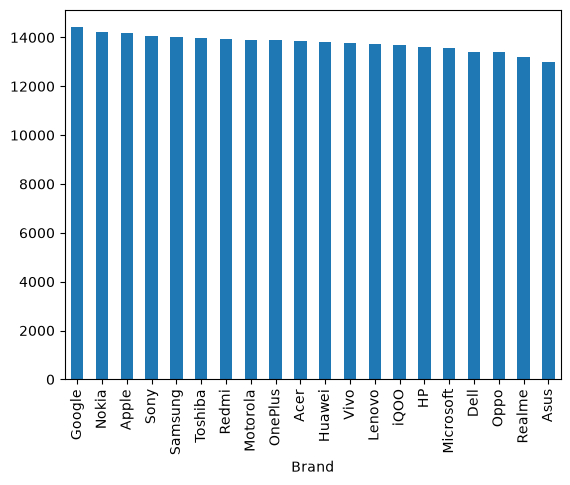

In [47]:
#Most Popular Brand
df.groupby(['Brand'])['Quantity Sold'].sum().sort_values(ascending=False).plot(kind='bar')

<Axes: ylabel='Brand'>

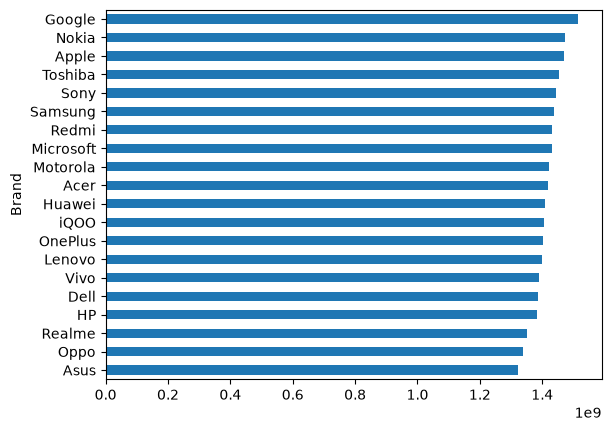

In [48]:
#Most Revenue Brand
df.groupby(['Brand'])['Revenue'].sum().sort_values().plot(kind='barh')

<Axes: xlabel='Product'>

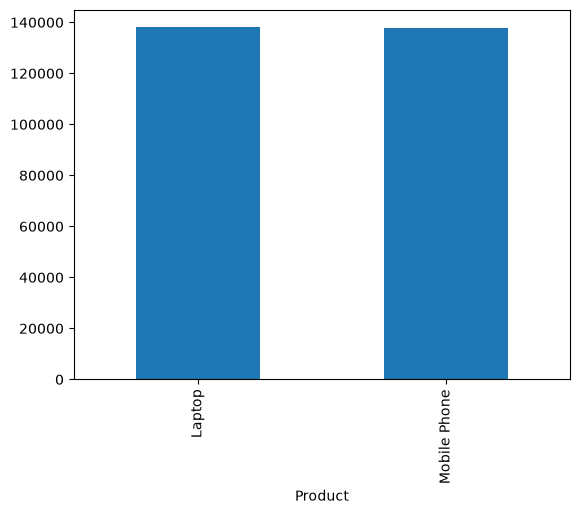

In [49]:
#Top Sales Product
df.groupby(['Product'])['Quantity Sold'].sum().sort_values(ascending=False).plot(kind='bar')

<Axes: >

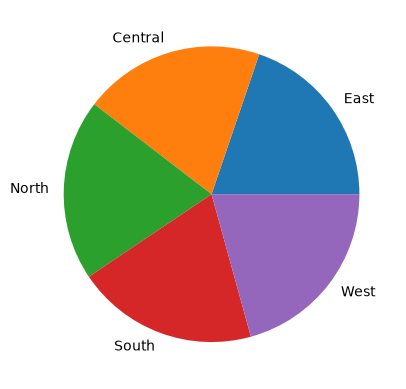

In [50]:
#Sales ber Region
df.groupby(['Region'])['Revenue'].sum().sort_values().plot(kind='pie')

In [51]:
#Total Sold Quantity ber Product
Total_Sold_Quantity=df.groupby(['Product'])['Quantity Sold'].sum()
Total_Sold_Quantity

Product
Laptop          138019
Mobile Phone    137670
Name: Quantity Sold, dtype: int64

In [52]:
#Revenue ber Product
Total_Revenue=df.groupby(['Product'])['Revenue'].sum()
Total_Revenue

Product
Laptop          14187414822
Mobile Phone    14091666300
Name: Revenue, dtype: int64

In [53]:
#Corretion Betwen Price & Quantity Sold
df.loc[:,['Price','Quantity Sold']].corr()*100

,Price,Quantity Sold
Price,100.000000,-0.222018
Quantity Sold,-0.222018,100.000000


<Axes: xlabel='Price', ylabel='Quantity Sold'>

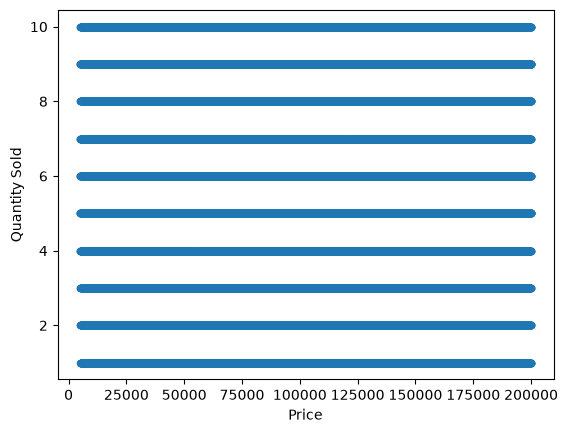

In [54]:
#Corretion Betwen Price & Quantity Sold
df.plot(kind='scatter',x='Price',y='Quantity Sold')

<Axes: xlabel='Brand'>

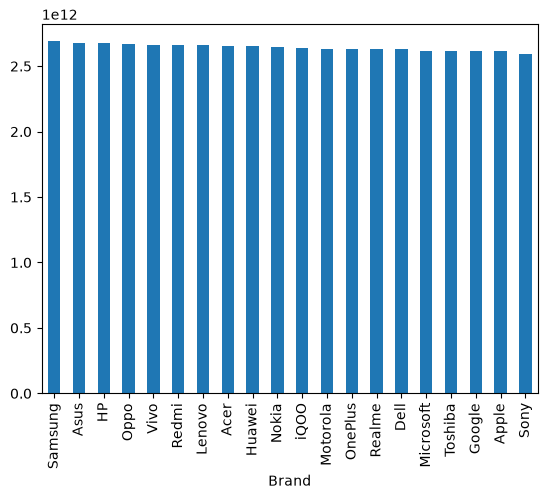

In [58]:
#Which brands have the highest average stock days?
df.groupby(['Brand'])['Days On Stock'].mean().sort_values(ascending=False).plot(kind='bar')

# Mobile & Laptop Sales Analysis – Project Summary

## 1. Project Overview
This project focuses on analyzing mobile phone and laptop sales data using Python to understand sales performance, revenue distribution, product demand, and inventory management.

## 2. Data Analysis
The analysis included:
- Calculating total revenue, average product prices, and total quantity sold.
- Comparing sales quantity and revenue across different brands.
- Comparing sales performance between laptops and mobile phones.
- Analyzing revenue distribution across different regions.
- Comparing total revenue and units sold for each product.
- Exploring the correlation between product prices and quantities sold.
- Analyzing average inventory holding days by brand.

## 3. Key Findings
- **Brand Performance:** Google recorded the highest sales quantity and total revenue among the analyzed brands.
- **Product Performance:** Laptops had slightly higher total sales quantity than mobile phones.
- **Regional Performance:** Revenue was compared across regions to identify differences in sales contribution.
- **Product-Level Analysis:** Revenue and units sold were compared to understand differences in product performance.
- **Price and Demand:** Correlation analysis was used to explore the relationship between product prices and sales quantity.
- **Inventory Management:** Samsung products had the highest average number of days in stock, indicating an area that may require further investigation.

## 4. Business Recommendations
- Investigate the factors behind Google's strong sales performance to understand what contributes to its results.
- Review regional sales performance to identify opportunities for growth.
- Examine the relationship between prices and sales quantities to better understand customer purchasing patterns.
- Investigate why Samsung products remain in stock longer, considering pricing, customer demand, product specifications, and marketing effectiveness.
- Consider targeted marketing campaigns or pricing adjustments if further analysis supports these actions.

## 5. Conclusion
This project demonstrates how Python can be used to transform raw sales data into meaningful business insights. The findings can help support data-driven decisions related to sales strategies, product performance, and inventory management.

## 6. Tools Used
Python | Pandas 